# Step 4: Exploratory data analysis
Objective: Find out which features to use in training and explore correlations.

## 1. Setup

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "src").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_prep import LEAKAGE_COLS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

train = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "train.parquet")

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

print(train.shape, "| overall late rate:", round(train["is_late"].mean(), 3))

(77176, 33) | overall late rate: 0.088


## 2. Late rate over time
### What are we looking for here?
The question is whether lateness is stable or changes with time, and if it changes, whether it moves with how busy the business is.
This matters for two reasons. For the business, it tells us whether lateness is a constant problem or a capacity problem that appears under pressure. For the model, it tells us whether time-related features (month, peak season) are worth engineering, and whether our chronological split will be a fair test. If late rates drift over time, the test period may behave differently from the training period.

### Why this chart?
We want to compare two quantities with different units over time: a count (orders) and a rate (percent late). The chart combines two views:
- Bars for volume, because volume is a quantity per month, and bars show “how much” well.
- A line for late rate, because a rate over consecutive months is a trend, and lines show direction and change.

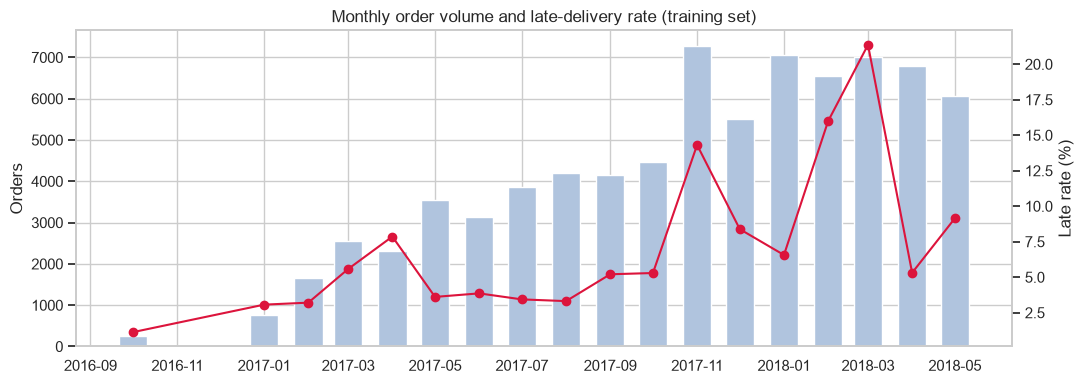

In [ ]:
monthly = (train.set_index("order_purchase_timestamp")
                .resample("MS")
                .agg(orders=("order_id", "count"), late_rate=("is_late", "mean")))
monthly = monthly[monthly["orders"] >= 100]   # skip months too small to be reliable, To-Do: re-evaluate this assumption

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(monthly.index, monthly["orders"], width=20, color="lightsteelblue")
ax1.set_ylabel("Orders")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["late_rate"] * 100, color="crimson", marker="o")
ax2.set_ylabel("Late rate (%)")
ax2.grid(False)
ax1.set_title("Monthly order volume and late-delivery rate (training set)")
save_fig("01_monthly_late_rate")
plt.show()

### Insights from this chart
Order volume grew about 15-fold from late 2016 to late 2017 and stayed elevated in 2018. The late-delivery rate sat around 3-4% in calm months of mid-2017 but spiked sharply in Nov 2017 (about 14%, coinciding with peak volume) and again in Feb-Mar 2018 (up to about 21%). Volume alone does not explain the spikes: Apr 2018 had volume similar to Mar 2018 but a late rate about 4x lower. This suggests operational factors beyond order volume, which we cannot identify from this data. Because only delivered orders are included, the most recent months may understate lateness.

## 3. Delivery time vs promise
### What are we looking for?
- How long do deliveries actually take? We want the typical time, the spread, and how bad the slow cases get.
- How does the promise compare? The estimate is the yardstick for “late”, so we want to know how much safety margin the promise usually carries.
- How severe is lateness? An order one day late and an order three weeks late both count as is_late = 1, but they’re very different business problems.

### Why this chart?
We have a single numeric variable and want its distribution, meaning its shape rather than an average. A histogram is the standard tool for that.

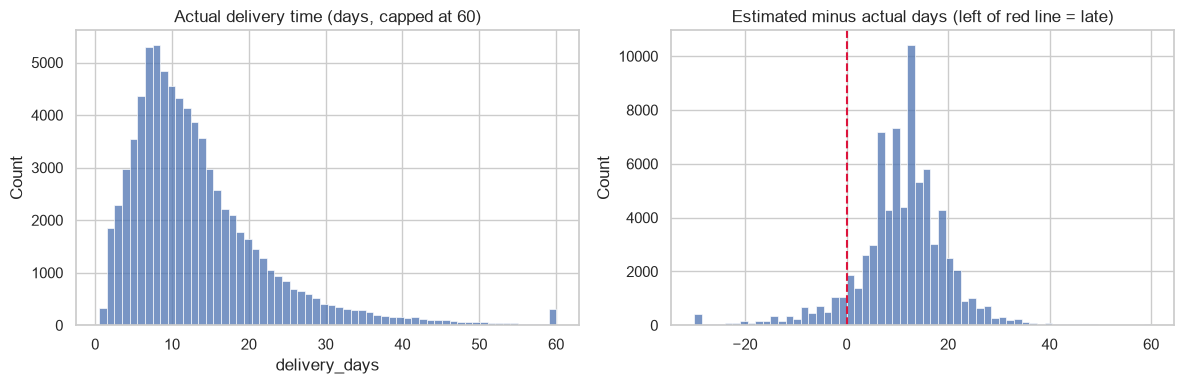

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(train["delivery_days"].clip(upper=60), bins=60, ax=ax[0])
ax[0].set_title("Actual delivery time (days, capped at 60)")

buffer = (train["estimated_days"] - train["delivery_days"]).clip(-30, 60)
sns.histplot(buffer, bins=60, ax=ax[1])
ax[1].axvline(0, color="crimson", linestyle="--")
ax[1].set_title("Estimated minus actual days (left of red line = late)")
save_fig("02_delivery_vs_estimate")
plt.show()

### Insights from this chart
Actual delivery times are right-skewed, typically 4-20 days with a peak around 8 days and a long tail beyond 30 days. The promised date leaves a median buffer of roughly 12 days, so lateness occurs only when an order exceeds an already generous estimate. The late orders are not clustered just past the deadline: lateness spreads out to 20+ days, and several hundred orders arrived over a month late (clipped at the -30 edge of the chart).

4. Geography

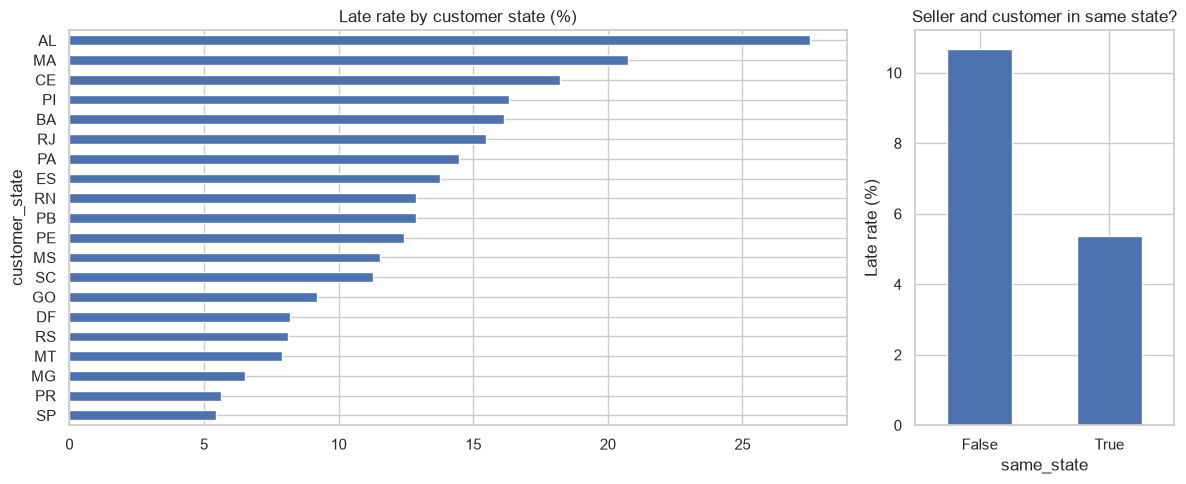

In [4]:
state = (train.groupby("customer_state")
              .agg(orders=("is_late", "size"), late_rate=("is_late", "mean"))
              .query("orders >= 300")
              .sort_values("late_rate"))

train["same_state"] = train["customer_state"] == train["seller_state"]

fig, ax = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [3, 1]})
(state["late_rate"] * 100).plot.barh(ax=ax[0], title="Late rate by customer state (%)")
(train.groupby("same_state")["is_late"].mean() * 100).plot.bar(
    ax=ax[1], title="Seller and customer in same state?", rot=0)
ax[1].set_ylabel("Late rate (%)")
save_fig("03_geography")
plt.show()

5. Order size, weight and cost

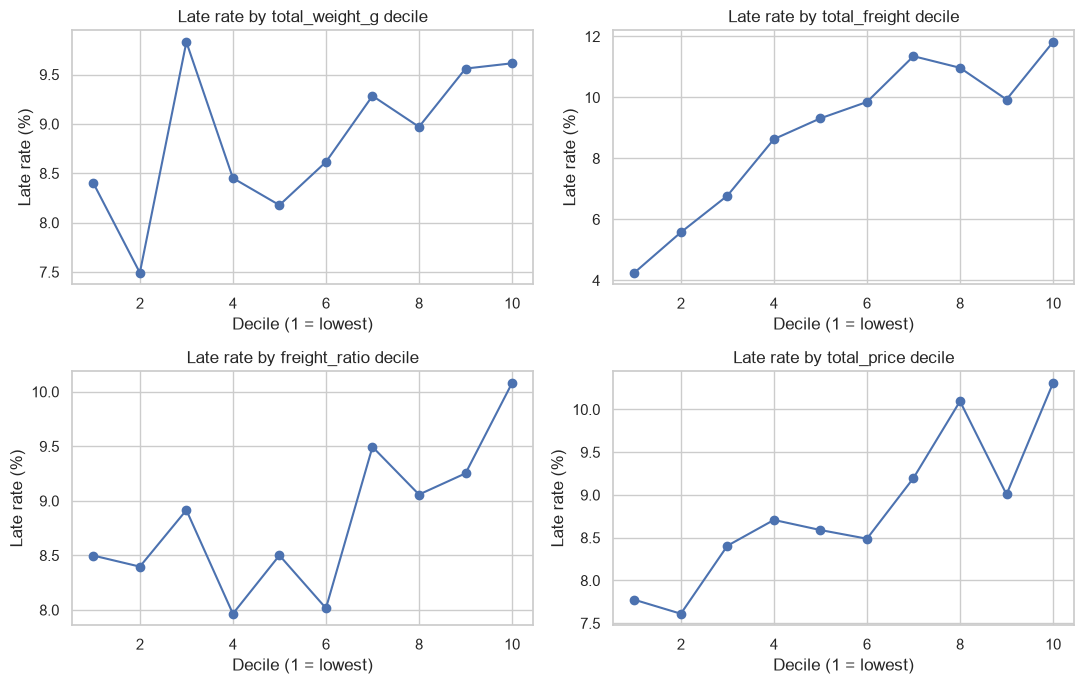

In [5]:
train["freight_ratio"] = (train["total_freight"] / train["total_price"]).replace([np.inf, -np.inf], np.nan)

cols = ["total_weight_g", "total_freight", "freight_ratio", "total_price"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), cols):
    bins = pd.qcut(train[col], q=10, duplicates="drop")
    rate = train.groupby(bins, observed=True)["is_late"].mean() * 100
    ax.plot(range(1, len(rate) + 1), rate.values, marker="o")
    ax.set_title(f"Late rate by {col} decile")
    ax.set_xlabel("Decile (1 = lowest)")
    ax.set_ylabel("Late rate (%)")
save_fig("04_order_characteristics")
plt.show()

6. Items, sellers, categories

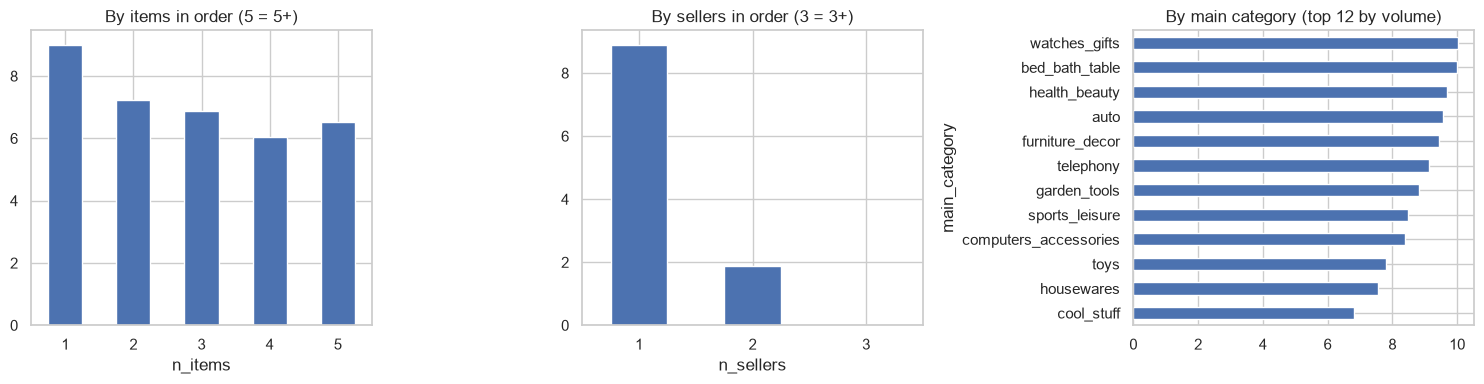

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
(train.groupby(train["n_items"].clip(upper=5))["is_late"].mean() * 100).plot.bar(
    ax=ax[0], title="By items in order (5 = 5+)", rot=0)
(train.groupby(train["n_sellers"].clip(upper=3))["is_late"].mean() * 100).plot.bar(
    ax=ax[1], title="By sellers in order (3 = 3+)", rot=0)

top = train["main_category"].value_counts().head(12).index
cat = (train[train["main_category"].isin(top)]
       .groupby("main_category")["is_late"].mean().sort_values() * 100)
cat.plot.barh(ax=ax[2], title="By main category (top 12 by volume)")
save_fig("05_items_sellers_categories")
plt.show()

7. Purchase timing

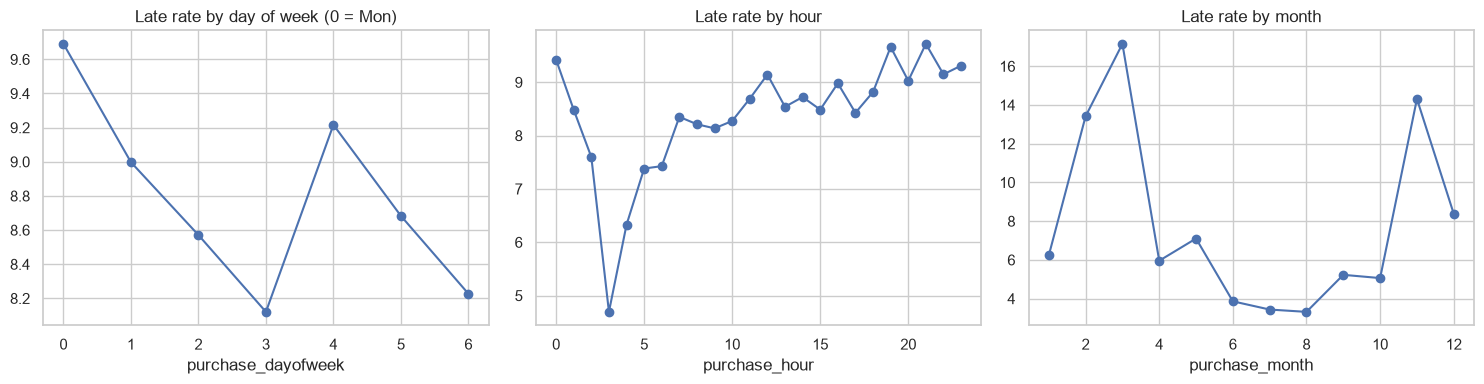

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col, title in zip(ax,
        ["purchase_dayofweek", "purchase_hour", "purchase_month"],
        ["day of week (0 = Mon)", "hour", "month"]):
    (train.groupby(col)["is_late"].mean() * 100).plot(ax=a, marker="o",
                                                      title=f"Late rate by {title}")
save_fig("06_purchase_timing")
plt.show()

8. Payment

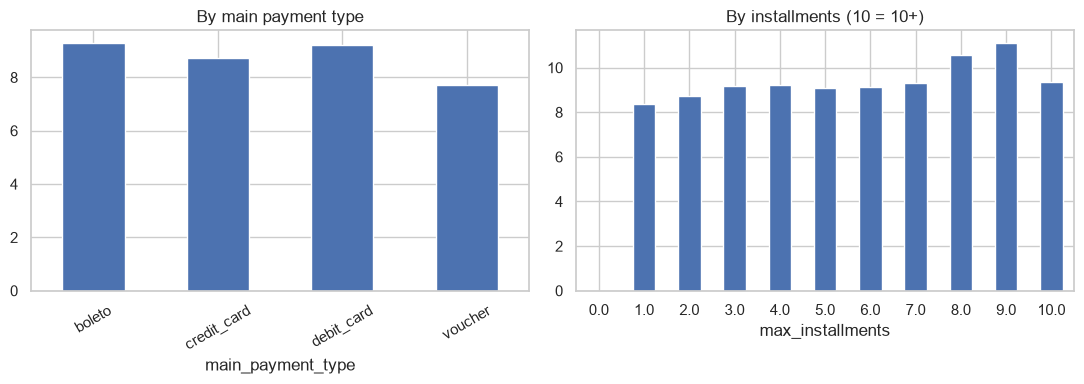

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
(train.groupby("main_payment_type")["is_late"].mean() * 100).plot.bar(
    ax=ax[0], title="By main payment type", rot=30)
(train.groupby(train["max_installments"].clip(upper=10))["is_late"].mean() * 100).plot.bar(
    ax=ax[1], title="By installments (10 = 10+)", rot=0)
save_fig("07_payment")
plt.show()

9. Business impact (uses review score, EDA only)

         mean  count
is_late             
0        4.28  69956
1        2.45   6659


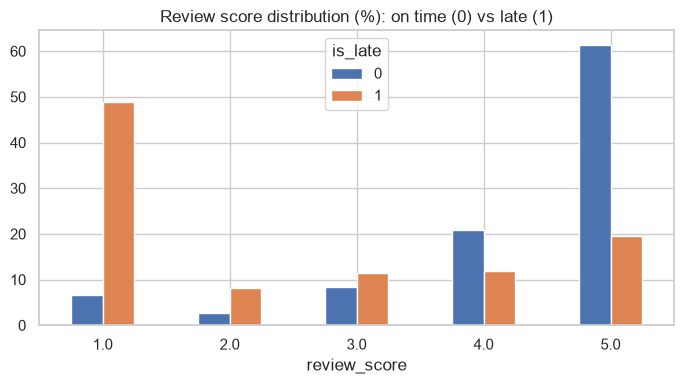

In [9]:
print(train.groupby("is_late")["review_score"].agg(["mean", "count"]).round(2))

dist = pd.crosstab(train["review_score"].round(), train["is_late"], normalize="columns") * 100
dist.plot.bar(figsize=(7, 4), rot=0,
              title="Review score distribution (%): on time (0) vs late (1)")
save_fig("08_review_impact")
plt.show()

10. Correlations with the target

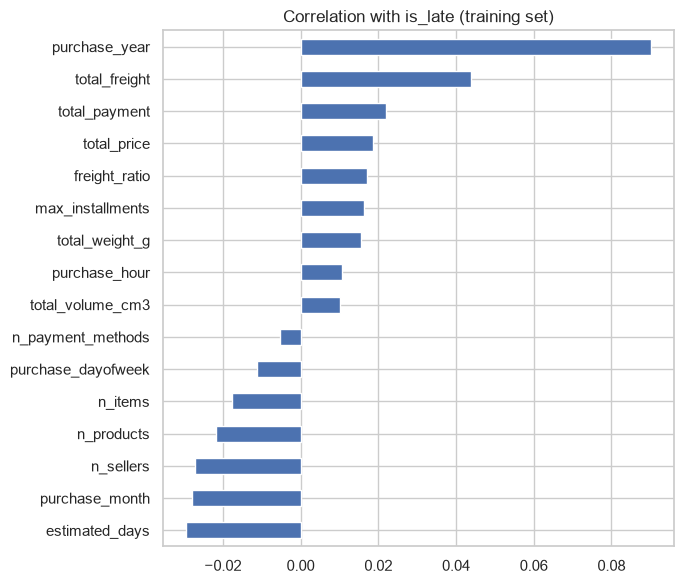

In [10]:
drop_cols = [c for c in LEAKAGE_COLS if c in train.columns] + ["customer_zip_code_prefix"]
num = train.select_dtypes("number").drop(columns=drop_cols, errors="ignore")
corr = num.corr()["is_late"].drop("is_late").sort_values()

corr.plot.barh(figsize=(7, 6), title="Correlation with is_late (training set)")
save_fig("09_correlations")
plt.show()

In [11]:
print(train["order_estimated_delivery_date"].dt.time.value_counts().head(3))

same_day = (train["order_delivered_customer_date"].dt.normalize()
            == train["order_estimated_delivery_date"].dt.normalize())
print("Delivered on the promised day:", same_day.sum(),
      f"({same_day.mean():.2%} of orders)")
print("...of which flagged late by timestamp:", (same_day & (train["is_late"] == 1)).sum())

order_estimated_delivery_date
00:00:00    77176
Name: count, dtype: int64
Delivered on the promised day: 945 (1.22% of orders)
...of which flagged late by timestamp: 945


11. Insights (to be added)
seasonality
geography
what the review gap says about the business cost
which order characteristics matter most
a Hypotheses